
# Data Augmentation

## Project: Retinopathy Detection System

### Objectives
1. Load training, validation and testing datasets.
2. Analyze class imbalance.
3. Apply image rotation.
4. Apply horizontal flipping.
5. Apply zoom augmentation.
6. Apply brightness and contrast adjustment.
7. Visualize original and augmented images.
8. Calculate class weights for balanced training.

### Dataset
APTOS 2019 Blindness Detection

### Augmentation Techniques
- Rotation
- Horizontal Flipping
- Zoom Transformation
- Brightness Adjustment
- Contrast Adjustment

### Important
Augmentation will only be applied to training images.
Validation and testing images will remain unchanged.


In [1]:

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os

from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

# Dataset paths
BASE = Path("../data/raw/aptos/aptos2019-blindness-detection")

TRAIN_DIR = BASE / "train_images"

SPLIT_DIR = Path("../data/processed/splits")

# Load dataset splits
train_df = pd.read_csv(SPLIT_DIR / "train_split.csv")

val_df = pd.read_csv(SPLIT_DIR / "validation_split.csv")

test_df = pd.read_csv(SPLIT_DIR / "internal_test_split.csv")

print("Dataset loaded successfully!")

print("\nTraining samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Internal testing samples:", len(test_df))

print("\nTraining columns:")
print(train_df.columns.tolist())


Dataset loaded successfully!

Training samples: 2563
Validation samples: 549
Internal testing samples: 550

Training columns:
['id_code', 'diagnosis']


In [3]:

train_ids = set(train_df["id_code"])
val_ids = set(val_df["id_code"])
test_ids = set(test_df["id_code"])

print("Training and validation overlap:",
      len(train_ids & val_ids))

print("Training and testing overlap:",
      len(train_ids & test_ids))

print("Validation and testing overlap:",
      len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("\nDataset separation verified successfully!")


Training and validation overlap: 0
Training and testing overlap: 0
Validation and testing overlap: 0

Dataset separation verified successfully!


Training Class Distribution:


diagnosis
0    1263
1     259
2     699
3     135
4     207
Name: count, dtype: int64

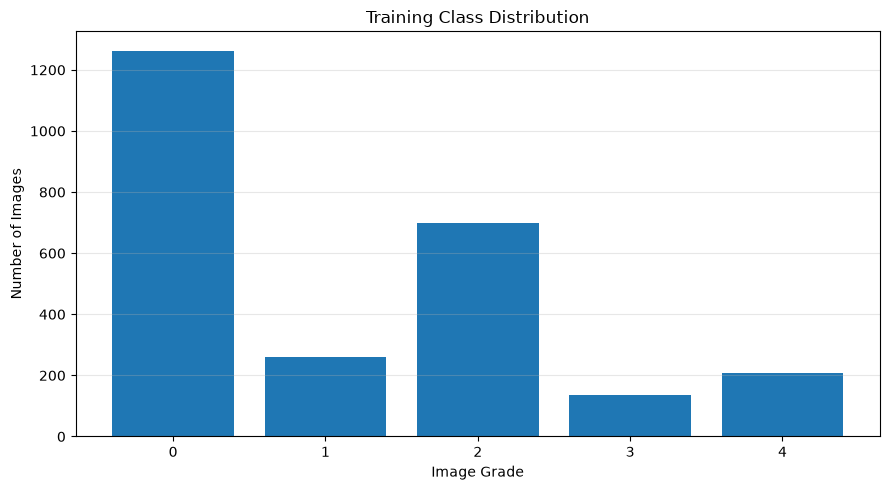

In [4]:

class_counts = (
    train_df["diagnosis"]
    .value_counts()
    .sort_index()
)

print("Training Class Distribution:")
display(class_counts)

plt.figure(figsize=(9, 5))

plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.title("Training Class Distribution")
plt.xlabel("Image Grade")
plt.ylabel("Number of Images")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Image ID: 38f1901f214a
Image shape: (300, 300, 3)


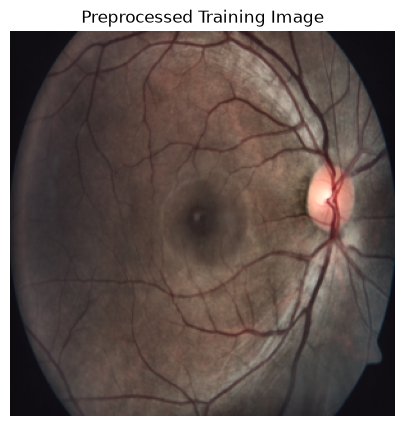

In [5]:

def load_retinal_image(image_id):

    image_path = TRAIN_DIR / (str(image_id) + ".png")

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Remove unnecessary black borders
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    mask = gray > 10

    if np.any(mask):
        coords = cv2.findNonZero(mask.astype(np.uint8))
        x, y, w, h = cv2.boundingRect(coords)

        margin = int(max(w, h) * 0.02)

        x1 = max(0, x - margin)
        y1 = max(0, y - margin)
        x2 = min(image.shape[1], x + w + margin)
        y2 = min(image.shape[0], y + h + margin)

        image = image[y1:y2, x1:x2]

    # Apply CLAHE
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l = clahe.apply(l)

    image = cv2.cvtColor(
        cv2.merge((l, a, b)),
        cv2.COLOR_LAB2RGB
    )

    # Common working resolution
    image = cv2.resize(
        image,
        (300, 300),
        interpolation=cv2.INTER_AREA
    )

    return image


# Load one sample
sample_id = train_df.iloc[0]["id_code"]

original_image = load_retinal_image(sample_id)

print("Image ID:", sample_id)
print("Image shape:", original_image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(original_image)
plt.title("Preprocessed Training Image")
plt.axis("off")
plt.show()


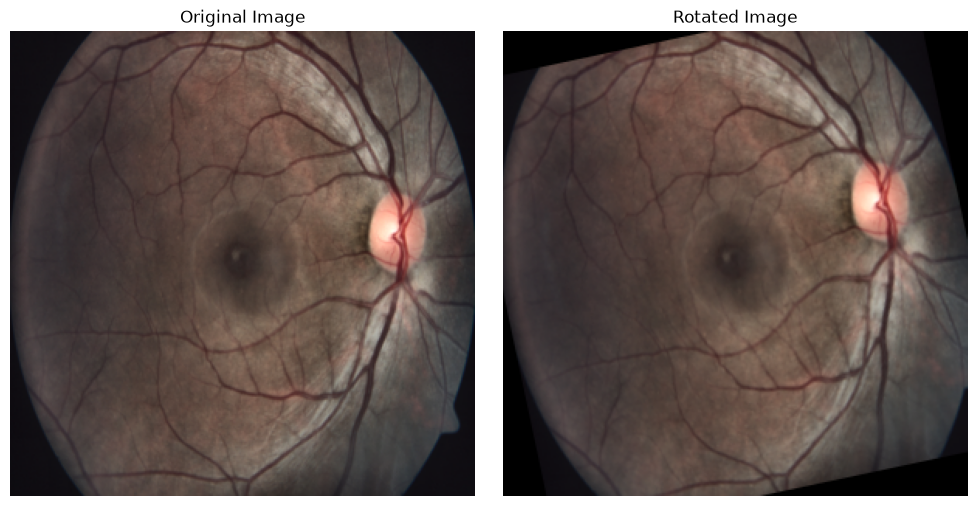

In [6]:

def rotate_image(image, angle=None):

    if angle is None:
        angle = random.uniform(-15, 15)

    h, w = image.shape[:2]

    center = (w // 2, h // 2)

    matrix = cv2.getRotationMatrix2D(
        center,
        angle,
        1.0
    )

    rotated = cv2.warpAffine(
        image,
        matrix,
        (w, h),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )

    return rotated


rotated_image = rotate_image(original_image, 12)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)
plt.title("Rotated Image")
plt.axis("off")

plt.tight_layout()
plt.show()


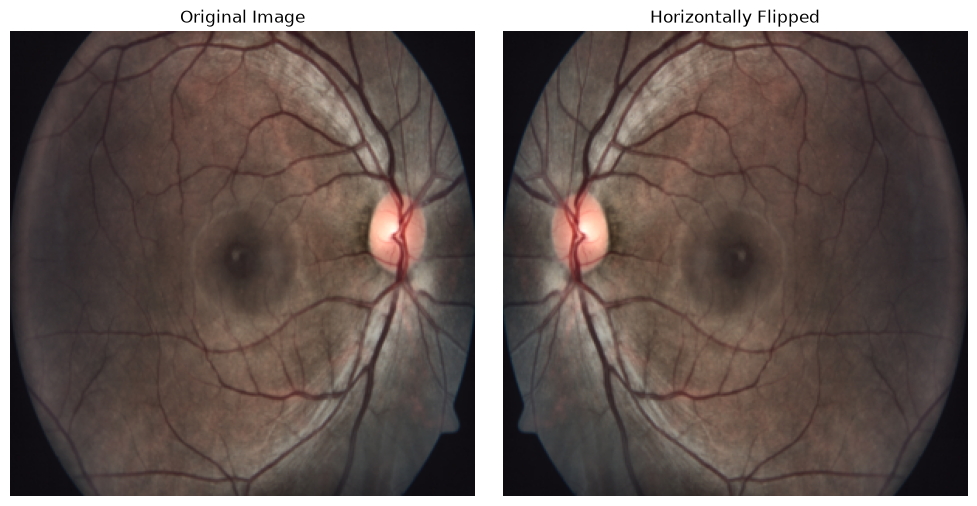

In [7]:

def horizontal_flip(image):

    return cv2.flip(image, 1)


flipped_image = horizontal_flip(original_image)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(flipped_image)
plt.title("Horizontally Flipped")
plt.axis("off")

plt.tight_layout()
plt.show()


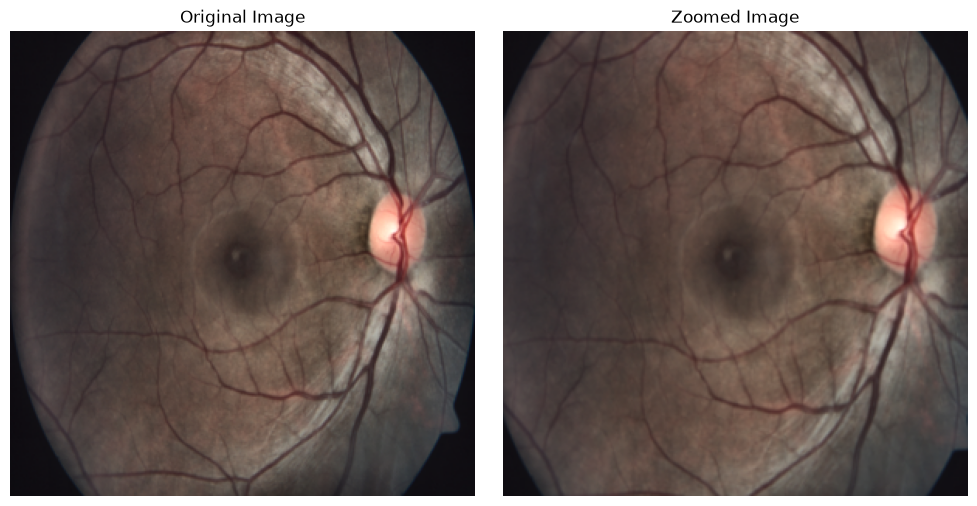

In [8]:

def zoom_image(image, zoom=None):

    if zoom is None:
        zoom = random.uniform(0.90, 1.10)

    h, w = image.shape[:2]

    new_h = int(h * zoom)
    new_w = int(w * zoom)

    resized = cv2.resize(
        image,
        (new_w, new_h)
    )

    if zoom >= 1.0:

        # Center crop
        start_y = (new_h - h) // 2
        start_x = (new_w - w) // 2

        result = resized[
            start_y:start_y + h,
            start_x:start_x + w
        ]

    else:

        # Place zoomed-out image on a black canvas
        result = np.zeros_like(image)

        start_y = (h - new_h) // 2
        start_x = (w - new_w) // 2

        result[
            start_y:start_y + new_h,
            start_x:start_x + new_w
        ] = resized

    return result


zoomed_image = zoom_image(original_image, 1.10)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(zoomed_image)
plt.title("Zoomed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


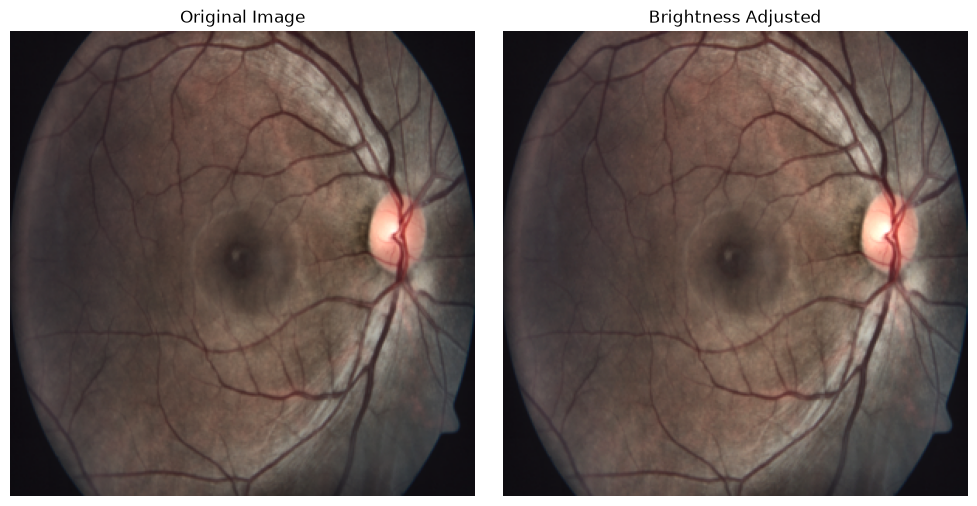

In [9]:

def adjust_brightness(image, factor=None):

    if factor is None:
        factor = random.uniform(0.90, 1.10)

    adjusted = image.astype(np.float32) * factor

    return np.clip(
        adjusted,
        0,
        255
    ).astype(np.uint8)


bright_image = adjust_brightness(
    original_image,
    1.10
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bright_image)
plt.title("Brightness Adjusted")
plt.axis("off")

plt.tight_layout()
plt.show()


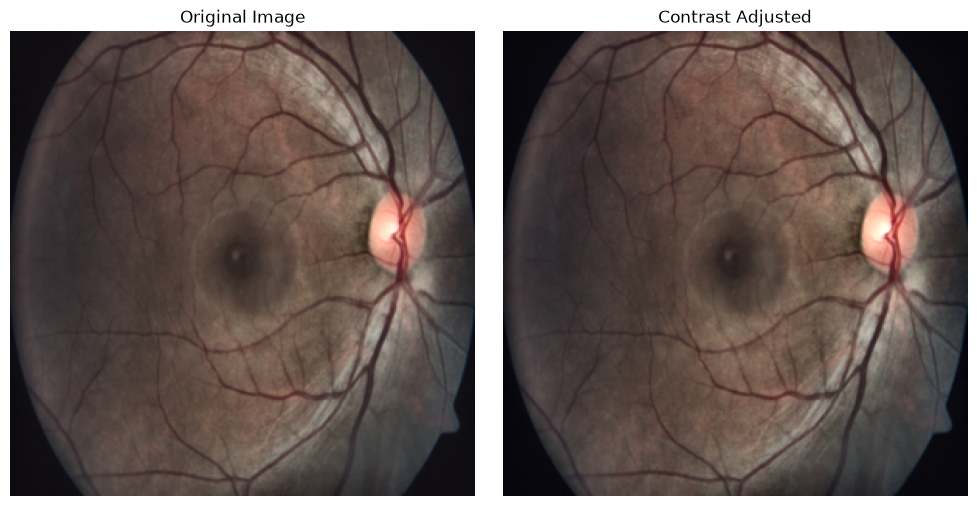

In [10]:

def adjust_contrast(image, factor=None):

    if factor is None:
        factor = random.uniform(0.90, 1.10)

    mean = np.mean(
        image,
        axis=(0, 1),
        keepdims=True
    )

    adjusted = (
        image.astype(np.float32) - mean
    ) * factor + mean

    return np.clip(
        adjusted,
        0,
        255
    ).astype(np.uint8)


contrast_image = adjust_contrast(
    original_image,
    1.10
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_image)
plt.title("Contrast Adjusted")
plt.axis("off")

plt.tight_layout()
plt.show()


Original shape: (300, 300, 3)
Augmented shape: (300, 300, 3)


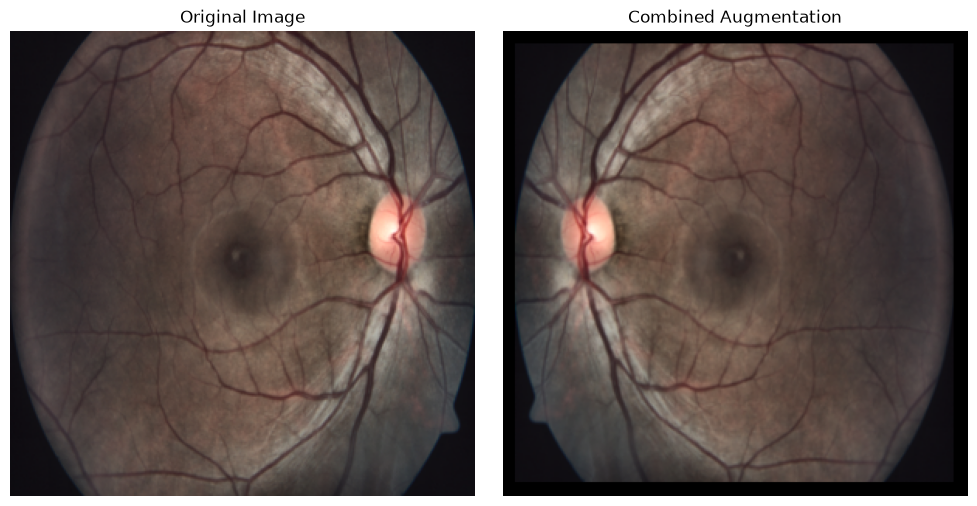

In [11]:

def augment_image(image):

    augmented = image.copy()

    # Random rotation
    if random.random() < 0.5:
        augmented = rotate_image(augmented)

    # Random horizontal flip
    if random.random() < 0.5:
        augmented = horizontal_flip(augmented)

    # Random zoom
    if random.random() < 0.5:
        augmented = zoom_image(augmented)

    # Random brightness
    if random.random() < 0.5:
        augmented = adjust_brightness(augmented)

    # Random contrast
    if random.random() < 0.5:
        augmented = adjust_contrast(augmented)

    return augmented


# Generate one augmented sample
augmented_image = augment_image(original_image)

print("Original shape:", original_image.shape)
print("Augmented shape:", augmented_image.shape)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image)
plt.title("Combined Augmentation")
plt.axis("off")

plt.tight_layout()
plt.show()


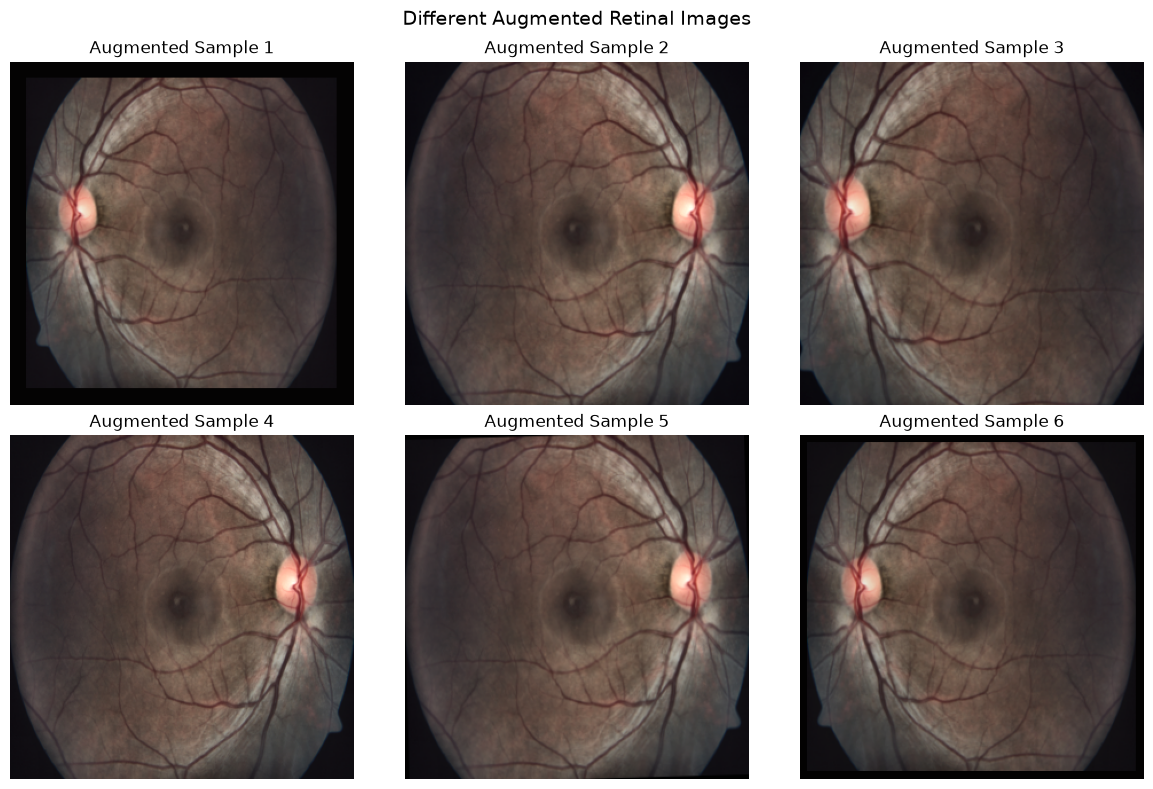

In [12]:

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):

    augmented = augment_image(original_image)

    ax.imshow(augmented)
    ax.set_title(f"Augmented Sample {i + 1}")
    ax.axis("off")

plt.suptitle(
    "Different Augmented Retinal Images",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [13]:

classes = np.sort(
    train_df["diagnosis"].unique()
)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"].values
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Calculated Class Weights:")

for cls, weight in class_weights.items():
    print(f"Grade {cls}: {weight:.4f}")


Calculated Class Weights:
Grade 0: 0.4059
Grade 1: 1.9792
Grade 2: 0.7333
Grade 3: 3.7970
Grade 4: 2.4763


In [14]:

print("========== DATA AUGMENTATION SUMMARY ==========")

print("\nOriginal Training Images:", len(train_df))

print("Validation Images:", len(val_df))

print("Internal Testing Images:", len(test_df))

print("\nAugmentation Techniques:")
print("1. Rotation")
print("2. Horizontal Flipping")
print("3. Zoom")
print("4. Brightness Adjustment")
print("5. Contrast Adjustment")

print("\nClass Weights:")
for grade, weight in class_weights.items():
    print(f"Grade {grade}: {weight:.4f}")

print("\nAugmentation is applied only to training images.")
print("Validation and testing images remain unchanged.")

print("\n========== COMPLETED ==========")


========== DATA AUGMENTATION SUMMARY ==========

Original Training Images: 2563
Validation Images: 549
Internal Testing Images: 550

Augmentation Techniques:
1. Rotation
2. Horizontal Flipping
3. Zoom
4. Brightness Adjustment
5. Contrast Adjustment

Class Weights:
Grade 0: 0.4059
Grade 1: 1.9792
Grade 2: 0.7333
Grade 3: 3.7970
Grade 4: 2.4763

Augmentation is applied only to training images.
Validation and testing images remain unchanged.

========== COMPLETED ==========


In [15]:

# Create preview folder
PREVIEW_DIR = Path(
    "../data/processed/augmentation_preview"
)

PREVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save original sample
cv2.imwrite(
    str(PREVIEW_DIR / "original.png"),
    cv2.cvtColor(
        original_image,
        cv2.COLOR_RGB2BGR
    )
)

# Save augmented samples
for i in range(5):

    augmented = augment_image(original_image)

    cv2.imwrite(
        str(PREVIEW_DIR / f"augmented_{i+1}.png"),
        cv2.cvtColor(
            augmented,
            cv2.COLOR_RGB2BGR
        )
    )

print("Preview images saved successfully!")
print("Location:", PREVIEW_DIR)


Preview images saved successfully!
Location: ..\data\processed\augmentation_preview



## Conclusion

In this experiment, different data augmentation
techniques were implemented to improve the
diversity of retinal training images.

The following techniques were explored:

1. Rotation
2. Horizontal Flipping
3. Zoom Transformation
4. Brightness Adjustment
5. Contrast Adjustment
6. Combined Random Augmentation
7. Class Weight Calculation

The augmented samples were visually inspected.

Class weights were calculated to address
class imbalance during model training.

Only training images will undergo random
augmentation. Validation and testing datasets
will remain unchanged.

### Future Work
- Deep Learning Model Development
- EfficientNetB3 Training
- MobileNetV2 Training
- Hybrid Feature Fusion Architecture
- Model Evaluation and Comparison
